# ASSIGNMENT 6 — Recurrent Neural Network (RNN)
**Họ và tên:** Trần Đình Hiếu  **MSV:** B23DCCE034

## Notebook 03 — RNN với **PyTorch** cho 2 bộ dữ liệu

Dùng `torch.nn.RNN` + `nn.Linear`, tự viết vòng lặp huấn luyện (PyTorch không có `fit` sẵn), `DataLoader`, autograd thay cho BPTT thủ công, `clip_grad_norm_`, early stopping.

Kiến trúc giống 2 notebook trước: `RNN(1 → 64, tanh) → h_T → Linear(64 → 1)`; Adam lr = 1e-3, batch 32, clip 1.0, patience 15.

In [1]:
import os, json, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('PyTorch', torch.__version__, '| device:', device)

PyTorch 2.14.0+cpu | device: cpu


## Dữ liệu & tiền xử lý (dùng chung cho cả 3 thư viện)

| Bộ dữ liệu | Nguồn | Chuỗi thời gian dự báo | Cửa sổ (window) |
|---|---|---|---|
| **E-commerce service process** | `olist_orders_dataset.csv` (Olist, Brazil) | Số đơn hàng được đặt mỗi ngày (15/01/2017 → 22/08/2018) | 14 ngày |
| **Stock** | `indexProcessed.csv` | Giá đóng cửa (USD) chỉ số NASDAQ – `IXIC` (2010 → 05/2021) | 30 phiên |

Các bước:
1. Gom chuỗi theo ngày (đơn hàng) / lọc chỉ số (cổ phiếu).
2. Chia **theo thời gian**: 80% đầu là train, 20% cuối là test (không xáo trộn để tránh rò rỉ thông tin tương lai).
3. Chuẩn hóa — chỉ dùng thống kê của tập train:
   * E-commerce: **Min-Max** về [0, 1].
   * Stock: **chuẩn hóa tương đối** $x'_k = (x_k / x_{t-1} - 1)/s$ (chia cho giá phiên cuối của cửa sổ, $s$ = độ lệch chuẩn lợi suất ngày trên train). Giá NASDAQ giai đoạn test cao hơn hẳn train nên Min-Max sẽ buộc mạng phải *ngoại suy* ngoài [0,1]; cách chuẩn hóa tương đối biến chuỗi thành dừng.
4. Tạo mẫu bằng **cửa sổ trượt**: $X = [x_{t-w}, \dots, x_{t-1}]$ → $y = x_t$ (bài toán *many-to-one*).
5. Đánh giá trên thang giá trị gốc bằng RMSE, MAE, MAPE, $R^2$ và so sánh với **baseline naive** ($\hat{x}_t = x_{t-1}$).

In [2]:
DATA_DIR = '.'          # thư mục chứa 2 file CSV
os.makedirs('figures', exist_ok=True)
os.makedirs('results', exist_ok=True)

def load_ecommerce():
    o = pd.read_csv(f'{DATA_DIR}/olist_orders_dataset.csv', parse_dates=['order_purchase_timestamp'])
    s = o.set_index('order_purchase_timestamp').resample('D').size().astype(float)
    s = s['2017-01-15':'2018-08-22']
    s.name = 'orders_per_day'
    return s

def load_stock(index='IXIC', start='2010-01-01'):
    d = pd.read_csv(f'{DATA_DIR}/indexProcessed.csv', parse_dates=['Date'])
    d = d[d['Index'] == index].set_index('Date').sort_index()
    s = d.loc[start:, 'CloseUSD'].astype(float)
    s.name = f'{index}_close_usd'
    return s

class MinMaxScaler1D:
    def fit(self, x):
        self.min, self.max = float(np.min(x)), float(np.max(x))
        return self
    def transform(self, x):
        return (np.asarray(x) - self.min) / (self.max - self.min)
    def inverse_transform(self, x):
        return np.asarray(x) * (self.max - self.min) + self.min

def prepare(series, window, scaling='minmax', train_ratio=0.8):
    # scaling='minmax'  : x' = (x - min) / (max - min), fit trên train.
    # scaling='relative': x' = (x / x_{t-1} - 1) / s  — chuẩn hóa theo giá cuối cửa sổ (s = độ lệch chuẩn lợi suất train),
    #                     giúp chuỗi không dừng (giá cổ phiếu) trở nên dừng và không phải ngoại suy.
    values = series.values.astype(np.float64)
    n_train = int(len(values) * train_ratio)
    target_idx = np.arange(window, len(values))
    base = values[target_idx - 1]                                   # giá trị ngay trước mục tiêu
    windows = np.stack([values[i - window:i] for i in target_idx])  # (N, T)
    targets = values[target_idx]
    is_train = target_idx < n_train
    if scaling == 'minmax':
        scaler = MinMaxScaler1D().fit(values[:n_train])
        X, y = scaler.transform(windows), scaler.transform(targets)
        inverse = lambda y_s, b: scaler.inverse_transform(y_s)
    else:
        s = float(np.std(targets[is_train] / base[is_train] - 1))
        X, y = (windows / base[:, None] - 1) / s, (targets / base - 1) / s
        inverse = lambda y_s, b: (np.asarray(y_s) * s + 1) * b
    test_base = base[~is_train]
    return dict(name=series.name, series=series, window=window, scaling=scaling,
                X_train=X[is_train][..., None], y_train=y[is_train][:, None],     # (N, T, 1), (N, 1)
                X_test=X[~is_train][..., None], y_test=y[~is_train][:, None],
                dates_test=series.index[target_idx[~is_train]],
                y_test_orig=targets[~is_train],
                naive_test=test_base,                                   # baseline: giá trị hôm trước
                to_original=lambda y_s: inverse(np.ravel(y_s), test_base))

def regression_metrics(y_true, y_pred):
    y_true, y_pred = np.ravel(y_true), np.ravel(y_pred)
    err = y_pred - y_true
    mask = y_true != 0
    return dict(RMSE=float(np.sqrt(np.mean(err ** 2))),
                MAE=float(np.mean(np.abs(err))),
                MAPE=float(np.mean(np.abs(err[mask] / y_true[mask])) * 100),
                R2=float(1 - np.sum(err ** 2) / np.sum((y_true - y_true.mean()) ** 2)))

DATASETS = {
    'ecommerce': prepare(load_ecommerce(), window=14, scaling='minmax'),
    'stock':     prepare(load_stock('IXIC'), window=30, scaling='relative'),
}
for k, d in DATASETS.items():
    print(f"{k:10s} | series={len(d['series'])} | X_train={d['X_train'].shape} | X_test={d['X_test'].shape}")

ecommerce  | series=585 | X_train=(454, 14, 1) | X_test=(117, 14, 1)
stock      | series=2871 | X_train=(2266, 30, 1) | X_test=(575, 30, 1)


## 1. Mô hình

* `nn.RNN(input_size, hidden_size, batch_first=True)` nhận tensor `(B, T, D)` và trả về `(output, h_n)`; `output[:, -1]` là $h_T$.
* Công thức của PyTorch: $h_t=\tanh(W_{ih}x_t + b_{ih} + W_{hh}h_{t-1} + b_{hh})$ — có 2 vector bias.
* Khởi tạo $W_{hh}$ trực giao như bản scratch.

In [3]:
class RNNRegressor(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=1):
        super().__init__()
        self.rnn = nn.RNN(input_size, hidden_size, num_layers=num_layers, nonlinearity='tanh', batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)
        for name, p in self.rnn.named_parameters():
            if 'weight_hh' in name: nn.init.orthogonal_(p)
            elif 'bias' in name:    nn.init.zeros_(p)

    def forward(self, x):                 # x: (B, T, 1)
        out, h_n = self.rnn(x)            # out: (B, T, H)
        return self.fc(out[:, -1, :])     # many-to-one: lấy h_T

print(RNNRegressor())
print('Số tham số:', sum(p.numel() for p in RNNRegressor().parameters()))

RNNRegressor(
  (rnn): RNN(1, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)
Số tham số: 4353


### Minh họa: `nn.RNN` ≡ vòng lặp tay với `nn.RNNCell`
`nn.RNN` chỉ là vòng lặp công thức $h_t$ qua thời gian (được tối ưu bằng C++/cuDNN).

In [4]:
rnn = nn.RNN(1, 4, batch_first=True)
cell = nn.RNNCell(1, 4)
cell.load_state_dict({'weight_ih': rnn.weight_ih_l0, 'weight_hh': rnn.weight_hh_l0, 'bias_ih': rnn.bias_ih_l0, 'bias_hh': rnn.bias_hh_l0})
x = torch.randn(2, 5, 1)
h = torch.zeros(2, 4)
for t in range(x.shape[1]):
    h = cell(x[:, t], h)
print('Giống nhau:', torch.allclose(rnn(x)[0][:, -1], h, atol=1e-6))

Giống nhau: True


## 2. Vòng lặp huấn luyện
Mỗi bước: `forward → loss → zero_grad → backward (autograd thực hiện BPTT) → clip_grad_norm_ → optimizer.step`.
10% cuối của train làm validation; giữ trọng số tốt nhất (early stopping).

In [5]:
HIDDEN, LR, BATCH, EPOCHS, PATIENCE, CLIP = 64, 1e-3, 32, 150, 15, 1.0

def train_torch(d, hidden=HIDDEN, verbose=10):
    torch.manual_seed(SEED)
    X = torch.tensor(d['X_train'], dtype=torch.float32)
    y = torch.tensor(d['y_train'], dtype=torch.float32)
    n_val = int(len(X) * 0.1)
    train_dl = DataLoader(TensorDataset(X[:-n_val], y[:-n_val]), batch_size=BATCH, shuffle=True)
    X_val, y_val = X[-n_val:].to(device), y[-n_val:].to(device)

    model = RNNRegressor(hidden_size=hidden).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.MSELoss()
    hist = {'train': [], 'val': []}
    best, best_state, wait = float('inf'), None, 0
    for ep in range(1, EPOCHS + 1):
        model.train(); total = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = loss_fn(model(xb), yb)
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), CLIP)
            opt.step()
            total += loss.item() * len(xb)
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(X_val), y_val).item()
        hist['train'].append(total / len(train_dl.dataset)); hist['val'].append(val_loss)
        if val_loss < best:
            best, best_state, wait = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
        if verbose and (ep % verbose == 0 or ep == 1):
            print(f'epoch {ep:3d} | train {hist["train"][-1]:.5f} | val {val_loss:.5f}')
        if wait >= PATIENCE:
            print(f'Early stopping tại epoch {ep}, best val = {best:.5f}')
            break
    model.load_state_dict(best_state)
    return model, hist

@torch.no_grad()
def predict(model, X):
    model.eval()
    return model(torch.tensor(X, dtype=torch.float32, device=device)).cpu().numpy()

In [6]:
def plot_results(key, history, y_true, y_pred, lib, train_label='train', val_label='val'):
    d = DATASETS[key]
    fig, axes = plt.subplots(1, 2, figsize=(15, 4), gridspec_kw={'width_ratios': [1, 2.3]})
    axes[0].plot(history['train'], label=train_label)
    if history.get('val'):
        axes[0].plot(history['val'], label=val_label)
    axes[0].set_title('Loss (MSE, dữ liệu đã chuẩn hóa)'); axes[0].set_xlabel('epoch'); axes[0].legend()
    axes[1].plot(d['dates_test'], y_true, label='Thực tế', color='black', lw=1.2)
    axes[1].plot(d['dates_test'], y_pred, label=f'Dự báo RNN ({lib})', color='tab:red', lw=1.2, alpha=.85)
    axes[1].set_title(f'{key}: dự báo 1 bước trên tập test'); axes[1].legend()
    plt.tight_layout()
    plt.savefig(f'figures/{lib}_{key}.png', dpi=110)
    plt.show()

def save_results(lib, key, metrics, naive, train_time, epochs, extra=None):
    out = dict(library=lib, dataset=key, metrics=metrics, naive_baseline=naive,
               train_time_sec=round(train_time, 2), epochs=epochs, **(extra or {}))
    with open(f'results/{lib}_{key}.json', 'w', encoding='utf-8') as f:
        json.dump(out, f, indent=2, ensure_ascii=False)
    return out

## 3. Dataset: E-commerce — số đơn hàng mỗi ngày (Olist)

epoch   1 | train 0.00838 | val 0.00838


epoch  10 | train 0.00298 | val 0.00251


epoch  20 | train 0.00247 | val 0.00112


epoch  30 | train 0.00234 | val 0.00104


epoch  40 | train 0.00231 | val 0.00133


...

epoch  60 | train 0.00225 | val 0.00101


epoch  70 | train 0.00217 | val 0.00112


epoch  80 | train 0.00215 | val 0.00102


Early stopping tại epoch 88, best val = 0.00085


,RMSE,MAE,MAPE,R2
PyTorch nn.RNN,40.123,31.465,15.398,0.647
Naive (x_t-1),49.345,37.684,17.589,0.466


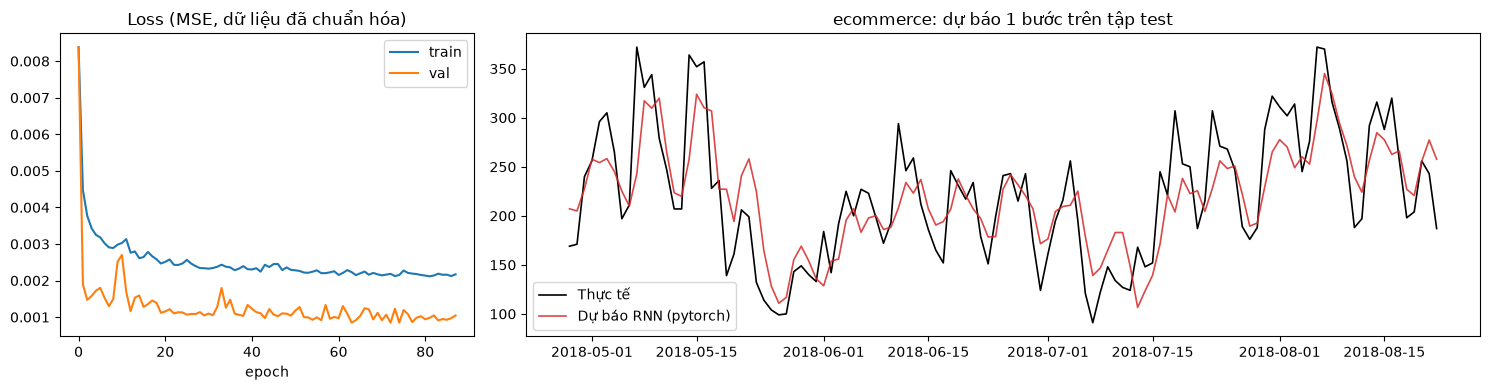

In [7]:
d = DATASETS['ecommerce']
t0 = time.time()
model, hist = train_torch(d)
train_time = time.time() - t0
y_pred = d['to_original'](predict(model, d['X_test']))
y_true = d['y_test_orig']
m_rnn = regression_metrics(y_true, y_pred)
m_naive = regression_metrics(y_true, d['naive_test'])
display(pd.DataFrame({'PyTorch nn.RNN': m_rnn, 'Naive (x_t-1)': m_naive}).T.round(3))
plot_results('ecommerce', hist, y_true, y_pred, 'pytorch')
n_params = sum(p.numel() for p in model.parameters())
res_ecommerce = save_results('pytorch', 'ecommerce', m_rnn, m_naive, train_time, len(hist['train']), {'n_params': n_params})
torch.save(model.state_dict(), 'results/pytorch_ecommerce.pt')

## 4. Dataset: Stock — NASDAQ (IXIC)

epoch   1 | train 0.95442 | val 1.51895


epoch  10 | train 0.92370 | val 1.48539


epoch  20 | train 0.81945 | val 1.62251


Early stopping tại epoch 25, best val = 1.48539


,RMSE,MAE,MAPE,R2
PyTorch nn.RNN,158.660,107.087,1.096,0.995
Naive (x_t-1),158.243,107.550,1.103,0.995


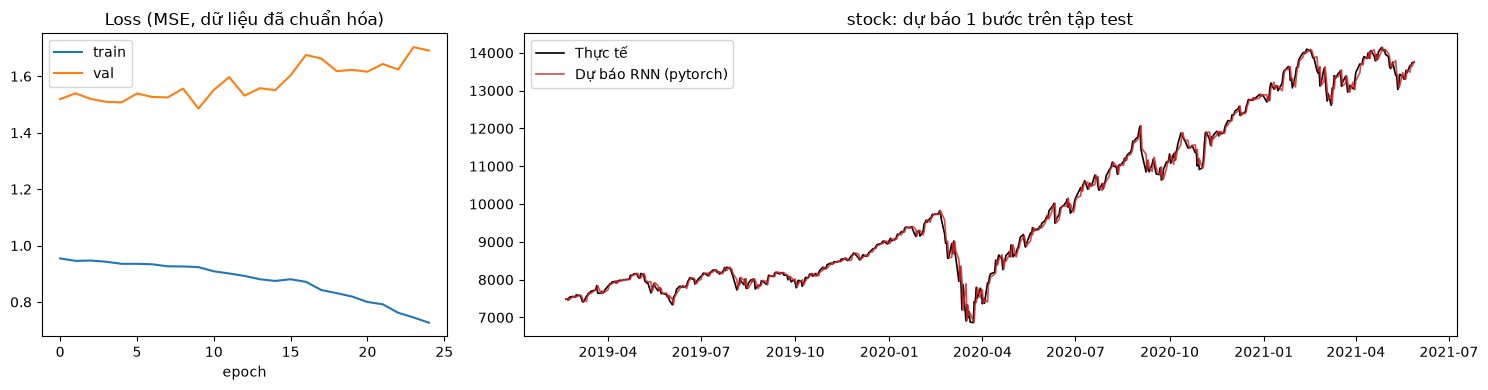

In [8]:
d = DATASETS['stock']
t0 = time.time()
model, hist = train_torch(d)
train_time = time.time() - t0
y_pred = d['to_original'](predict(model, d['X_test']))
y_true = d['y_test_orig']
m_rnn = regression_metrics(y_true, y_pred)
m_naive = regression_metrics(y_true, d['naive_test'])
display(pd.DataFrame({'PyTorch nn.RNN': m_rnn, 'Naive (x_t-1)': m_naive}).T.round(3))
plot_results('stock', hist, y_true, y_pred, 'pytorch')
n_params = sum(p.numel() for p in model.parameters())
res_stock = save_results('pytorch', 'stock', m_rnn, m_naive, train_time, len(hist['train']), {'n_params': n_params})
torch.save(model.state_dict(), 'results/pytorch_stock.pt')

## 5. Tổng kết & so sánh 3 cách cài đặt
(Đọc kết quả đã lưu ở `results/` bởi các notebook 01, 02, 03.)

In [9]:
rows = []
for lib in ['scratch', 'keras', 'pytorch']:
    for key in ['ecommerce', 'stock']:
        f = f'results/{lib}_{key}.json'
        if os.path.exists(f):
            r = json.load(open(f, encoding='utf-8'))
            rows.append({'library': lib, 'dataset': key, **r['metrics'], 'naive_RMSE': r['naive_baseline']['RMSE'],
                         'epochs': r['epochs'], 'time_s': r['train_time_sec'], 'params': r.get('n_params')})
summary = pd.DataFrame(rows).sort_values(['dataset', 'library'])
summary.to_csv('results/summary.csv', index=False)
summary.round(3)

,library,dataset,RMSE,MAE,MAPE,R2,naive_RMSE,epochs,time_s,params
2,keras,ecommerce,41.297,32.743,16.139,0.626,49.345,46,7.83,4289
4,pytorch,ecommerce,40.123,31.465,15.398,0.647,49.345,88,6.16,4353
0,scratch,ecommerce,42.511,34.421,17.487,0.604,49.345,52,1.00,4289
3,keras,stock,159.924,108.225,1.103,0.994,158.243,30,40.51,4289
5,pytorch,stock,158.660,107.087,1.096,0.995,158.243,25,8.69,4353
1,scratch,stock,158.298,107.273,1.098,0.995,158.243,22,4.39,4289


**Nhận xét**
* PyTorch linh hoạt: tự kiểm soát vòng lặp huấn luyện, autograd thay cho BPTT thủ công, dễ tùy biến (nhiều lớp, dropout, đầu ra nhiều bước…).
* Cả ba cách cài đặt (scratch, Keras, PyTorch) dùng cùng kiến trúc và siêu tham số → kết quả tương đương nhau; khác biệt nhỏ đến từ khởi tạo ngẫu nhiên và chi tiết cài đặt (PyTorch có 2 bias).
* Đối với dữ liệu dịch vụ e-commerce, RNN khai thác được mùa vụ tuần; với giá cổ phiếu, RNN chỉ tiệm cận baseline naive do tính chất gần như ngẫu nhiên của thị trường.